In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely import wkt
import pandas as pd
from shapely.geometry import Point
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [13]:
world_url = (
    "https://naciscdn.org/naturalearth/110m/"
    "cultural/ne_110m_admin_0_countries.zip"
)

world = gpd.read_file(world_url)

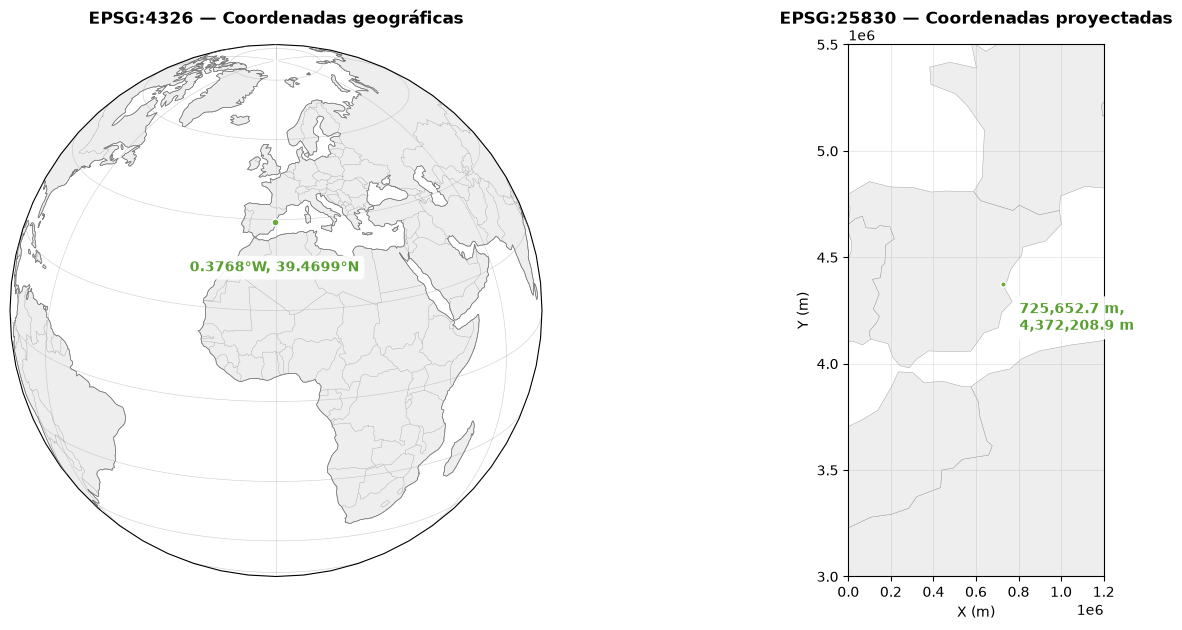

In [34]:
# ============================================================
# 1. PUNTO DE REFERENCIA
# ============================================================

lon = -0.3768
lat = 39.4699

punto_4326 = gpd.GeoDataFrame(
    {"nombre": ["Punto de referencia"]},
    geometry=[Point(lon, lat)],
    crs="EPSG:4326"
)

# Transformación a EPSG:25830
punto_25830 = punto_4326.to_crs(epsg=25830)

x_4326 = punto_4326.geometry.iloc[0].x
y_4326 = punto_4326.geometry.iloc[0].y

x_25830 = punto_25830.geometry.iloc[0].x
y_25830 = punto_25830.geometry.iloc[0].y

# Mantener dos versiones independientes
world_4326 = world.to_crs(epsg=4326)
world_25830 = world.to_crs(epsg=25830)

fig = plt.figure(
    figsize=(14, 7)
)


# PANEL IZQUIERDO — EPSG:4326
ax1 = fig.add_axes(
    [0.03, 0.12, 0.44, 0.76],
    projection=ccrs.Orthographic(
        central_longitude=0,
        central_latitude=20
    )
)

# obliga a Cartopy a representar todo el globo
ax1.set_global()

ax1.add_feature(
    cfeature.OCEAN,
    facecolor="white",
    zorder=0
)

ax1.add_feature(
    cfeature.LAND,
    facecolor="#eeeeee",
    edgecolor="#888888",
    linewidth=0.4,
    zorder=1
)

ax1.add_feature(
    cfeature.BORDERS,
    linewidth=0.25,
    edgecolor="#999999",
    zorder=2
)

ax1.coastlines(
    linewidth=0.5,
    color="#777777",
    zorder=3
)

ax1.gridlines(
    linewidth=0.4,
    color="#aaaaaa",
    alpha=0.6,
    linestyle="-",
    zorder=4
)

ax1.scatter(
    x_4326,
    y_4326,
    transform=ccrs.PlateCarree(),
    s=25,
    color="#6aaa3c",
    edgecolor="white",
    linewidth=1,
    zorder=10
)

ax1.annotate(
    f"{abs(x_4326):.4f}°W, {y_4326:.4f}°N",
    xy=(x_4326, y_4326),
    xycoords=ccrs.PlateCarree()._as_mpl_transform(ax1),
    xytext=(0, -28),
    textcoords="offset points",
    ha="center",
    va="top",
    fontsize=10,
    fontweight="bold",
    color="#5a9f32",
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="none",
        alpha=0.90
    ),
    zorder=11
)

ax1.set_title(
    "EPSG:4326 — Coordenadas geográficas",
    fontsize=12,
    fontweight="bold",
    pad=15
)

ax2 = fig.add_axes(
    [0.53, 0.12, 0.44, 0.76]
)

world_25830.plot(
    ax=ax2,
    facecolor="#eeeeee",
    edgecolor="#999999",
    linewidth=0.3
)

punto_25830.plot(
    ax=ax2,
    color="#6aaa3c",
    edgecolor="white",
    linewidth=1,
    markersize=15,
    zorder=10
)

ax2.annotate(
    f"{x_25830:,.1f} m,\n{y_25830:,.1f} m",
    xy=(x_25830, y_25830),
    xytext=(12, -12),
    textcoords="offset points",
    ha="left",
    va="top",
    fontsize=10,
    fontweight="bold",
    color="#5a9f32",
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="none",
        alpha=0.90
    ),
    zorder=11
)

ax2.set_xlim(
    0,
    1200000
)

ax2.set_ylim(
    3000000,
    5500000
)

ax2.set_xlabel(
    "X (m)",
    fontsize=10
)

ax2.set_ylabel(
    "Y (m)",
    fontsize=10
)

ax2.grid(
    True,
    linewidth=0.4,
    alpha=0.5
)

ax2.set_title(
    "EPSG:25830 — Coordenadas proyectadas",
    fontsize=12,
    fontweight="bold",
    pad=15
)


plt.savefig(
    "figuras/comparativa_CRS.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

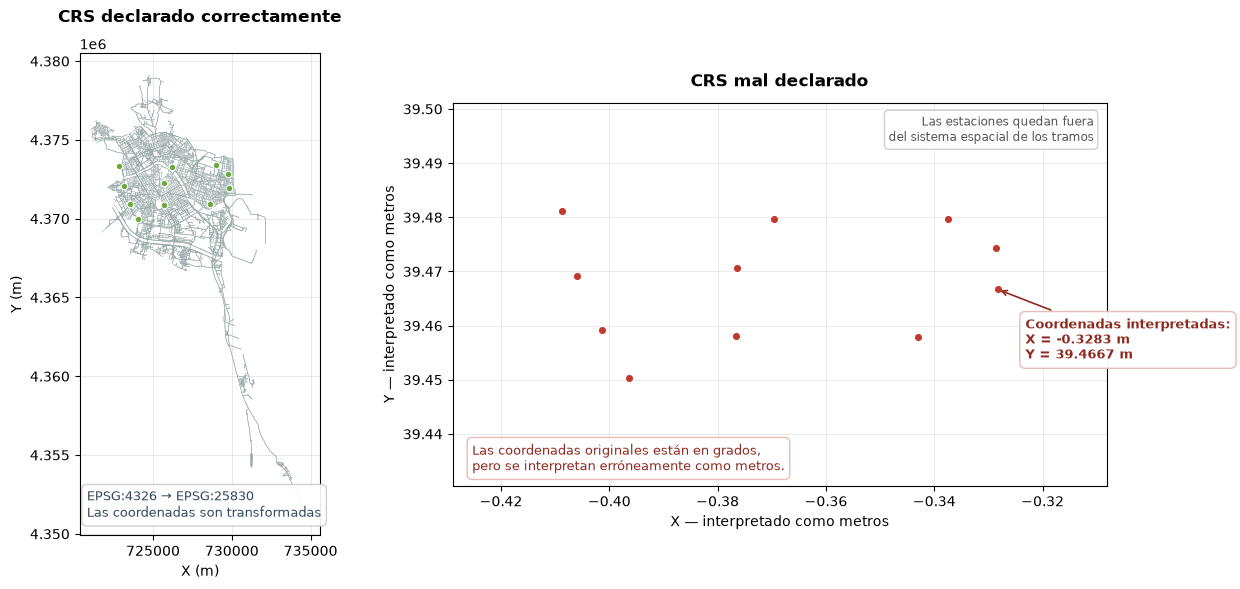

In [44]:
tramos_path = "datasets/working/callejero-cleaned.csv"
estaciones_path = "datasets/working/contaminacion-ambiental-valencia.csv"

tramos_df = pd.read_csv(
    tramos_path,
    sep=";"
)

estaciones_df = pd.read_csv(
    estaciones_path,
    sep=";"
)

tramos_df["geometry"] = tramos_df["geometry"].apply(
    wkt.loads
)

estaciones_df["geometry_station"] = estaciones_df[
    "geometry"
].apply(
    wkt.loads
)

tramos = gpd.GeoDataFrame(
    tramos_df,
    geometry="geometry",
    crs="EPSG:4326"
)

estaciones = gpd.GeoDataFrame(
    estaciones_df,
    geometry="geometry_station",
    crs="EPSG:4326"
)

tramos_25830 = tramos.to_crs(
    epsg=25830
)

est_ok = estaciones.to_crs(
    epsg=25830
)

est_mal = estaciones.set_crs(
    epsg=25830,
    allow_override=True
)

xmin, ymin, xmax, ymax = (
    tramos_25830.total_bounds
)

margin_x = (xmax - xmin) * 0.05
margin_y = (ymax - ymin) * 0.05

map_xlim = (
    xmin - margin_x,
    xmax + margin_x
)

map_ylim = (
    ymin - margin_y,
    ymax + margin_y
)

fig, (ax1, ax2) = plt.subplots(
    1,
    2,
    figsize=(14, 6)
)

tramos_25830.plot(
    ax=ax1,
    color="#95a5a6",
    linewidth=0.35,
    zorder=1
)

est_ok.plot(
    ax=ax1,
    color="#6aaa3c",
    edgecolor="white",
    linewidth=0.8,
    markersize=22,
    zorder=5
)

ax1.set_xlim(*map_xlim)
ax1.set_ylim(*map_ylim)

ax1.set_xlabel(
    "X (m)",
    fontsize=10
)

ax1.set_ylabel(
    "Y (m)",
    fontsize=10
)

ax1.grid(
    True,
    linewidth=0.4,
    alpha=0.5
)

ax1.set_title(
    "CRS declarado correctamente",
    fontsize=12,
    fontweight="bold",
    pad=12
)

ax1.text(
    0.03,
    0.03,
    "EPSG:4326 → EPSG:25830\n"
    "Las coordenadas son transformadas",
    transform=ax1.transAxes,
    fontsize=9,
    color="#34495e",
    verticalalignment="bottom",
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="#cccccc",
        alpha=0.92
    )
)

est_mal.plot(
    ax=ax2,
    color="#c0392b",
    edgecolor="white",
    linewidth=0.8,
    markersize=35,
    zorder=5
)

xmin_mal, ymin_mal, xmax_mal, ymax_mal = (
    est_mal.total_bounds
)

range_x_mal = xmax_mal - xmin_mal
range_y_mal = ymax_mal - ymin_mal

margin_x_mal = max(
    range_x_mal * 0.25,
    0.02
)

margin_y_mal = max(
    range_y_mal * 0.25,
    0.02
)

ax2.set_xlim(
    xmin_mal - margin_x_mal,
    xmax_mal + margin_x_mal
)

ax2.set_ylim(
    ymin_mal - margin_y_mal,
    ymax_mal + margin_y_mal
)

ax2.set_xlabel(
    "X — interpretado como metros",
    fontsize=10
)

ax2.set_ylabel(
    "Y — interpretado como metros",
    fontsize=10
)

ax2.grid(
    True,
    linewidth=0.4,
    alpha=0.5
)

ax2.set_title(
    "CRS mal declarado",
    fontsize=12,
    fontweight="bold",
    pad=12
)

ejemplo = est_mal.geometry.iloc[0]

ax2.annotate(
    f"Coordenadas interpretadas:\n"
    f"X = {ejemplo.x:.4f} m\n"
    f"Y = {ejemplo.y:.4f} m",
    xy=(ejemplo.x, ejemplo.y),
    xytext=(20, -20),
    textcoords="offset points",
    fontsize=9,
    fontweight="bold",
    color="#8e2b20",
    ha="left",
    va="top",
    arrowprops=dict(
        arrowstyle="->",
        color="#8e2b20",
        linewidth=1.2
    ),
    bbox=dict(
        boxstyle="round,pad=0.45",
        facecolor="white",
        edgecolor="#e6b8b2",
        alpha=0.95
    ),
    zorder=10
)


# ============================================================
# EXPLICACIÓN
# ============================================================

ax2.text(
    0.03,
    0.03,
    "Las coordenadas originales están en grados,\n"
    "pero se interpretan erróneamente como metros.",
    transform=ax2.transAxes,
    fontsize=9,
    color="#8e2b20",
    verticalalignment="bottom",
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="#e6b8b2",
        alpha=0.95
    )
)


# ============================================================
# INDICACIÓN DEL DESPLAZAMIENTO
# ============================================================

ax2.text(
    0.98,
    0.97,
    "Las estaciones quedan fuera\n"
    "del sistema espacial de los tramos",
    transform=ax2.transAxes,
    fontsize=8.5,
    color="#555555",
    ha="right",
    va="top",
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="#cccccc",
        alpha=0.9
    )
)

# fig.suptitle(
#     "Efecto de una declaración incorrecta del sistema de referencia",
#     fontsize=14,
#     fontweight="bold",
#     x=0.5,
#     y=0.99,
#     ha="center"
# )

plt.subplots_adjust(
    left=0.06,
    right=0.97,
    bottom=0.10,
    top=0.84,
    wspace=0.20
)

plt.savefig(
    "figuras/error_en_crs.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout()

plt.show()